# Дополнения к лабораторным работам №1-4 (по требованиям контрольной работы)

Ноутбук закрывает пункты требований, которых не было в основных работах:

- **ЛР1**: дисперсия и мода; выбросы через ящик с усами (1.5·IQR) и z-score; диаграммы рассеяния;
  3D-график; предобработка текста (нижний регистр, пунктуация, стоп-слова); кодирование One-Hot
  и стандартизация с сохранением выборки.
- **ЛР2**: иерархическая кластеризация с дендрограммой; k-distance график для DBSCAN;
  сравнение трех алгоритмов по силуэту, Calinski-Harabasz и Davies-Bouldin; 3D-визуализация кластеров.
- **ЛР3**: сравнение четырех моделей регрессии (линейная, дерево, случайный лес, бустинг);
  подбор гиперпараметров; эксперимент с TF-IDF признаками текста; взвешенное ансамблирование;
  график "фактические vs предсказанные значения".
- **ЛР4**: сравнение четырех моделей классификации (логрегрессия, дерево, лес, бустинг);
  голосование (soft voting); матрица ошибок; ROC-кривые всех моделей; важность признаков;
  устойчивость к переобучению (разрыв train/test); средние по классам.

Ноутбук самодостаточен: читает таблицу лабы №1 из Iceberg и сам готовит выборки.

In [1]:
# Модуль для работы с окружением (получение имени пользователя)
import os

# Классы PySpark: сессия и конфигурация
from pyspark.sql import SparkSession
from pyspark import SparkConf

# Функции над столбцами Spark
from pyspark.sql.functions import (col, desc, when, lit, concat, lower, mean, stddev,
                                   abs, explode, var_samp, regexp_replace)

# vector_to_array - разбор вектор-столбца на элементы (живет в ml.functions)
from pyspark.ml.functions import vector_to_array

# Трансформеры подготовки признаков
from pyspark.ml.feature import (VectorAssembler, StandardScaler, StringIndexer, OneHotEncoder,
                                Tokenizer, StopWordsRemover, HashingTF, IDF, PCA)
# Конвейер
from pyspark.ml import Pipeline

# Модели регрессии Spark ML
from pyspark.ml.regression import LinearRegression, DecisionTreeRegressor, RandomForestRegressor, GBTRegressor
# Модели классификации Spark ML
from pyspark.ml.classification import LogisticRegression, DecisionTreeClassifier, RandomForestClassifier, GBTClassifier

# Кластеризация Spark ML и оценка качества
from pyspark.ml.clustering import KMeans
from pyspark.ml.evaluation import ClusteringEvaluator, RegressionEvaluator, BinaryClassificationEvaluator

# Подбор гиперпараметров: сетка + валидационный сплит
from pyspark.ml.tuning import ParamGridBuilder, TrainValidationSplit

# pandas / numpy - таблицы и массивы на драйвере
import pandas as pd
import numpy as np

# Графики
import matplotlib.pyplot as plt
import seaborn as sns

# Инструменты sklearn для работы на небольших выборках в памяти
from sklearn.cluster import DBSCAN, KMeans as SkKMeans
from sklearn.neighbors import NearestNeighbors
from sklearn.metrics import (silhouette_score, calinski_harabasz_score, davies_bouldin_score,
                             precision_recall_fscore_support, roc_curve, auc,
                             confusion_matrix, f1_score)

# Иерархическая кластеризация scipy
from scipy.cluster.hierarchy import linkage, fcluster, dendrogram

# Стиль графиков
sns.set_theme(style="whitegrid")

In [2]:
# Имя пользователя из переменной окружения (каталог в HDFS)
user_name = os.getenv("USER")

# Подключаем Iceberg до старта JVM (пакеты разрешаются только spark-submit'ом)
os.environ["PYSPARK_SUBMIT_ARGS"] = (
    "--packages org.apache.iceberg:iceberg-spark-runtime-3.5_2.12:1.6.0 pyspark-shell"
)

# Объект конфигурации
conf = SparkConf()
# Имя приложения
conf.setAppName("lab supplements korolev")
# Кластер YARN, режим client
conf.setMaster("yarn")
conf.set("spark.submit.deployMode", "client")
# Ресурсы исполнителей
conf.set("spark.executor.memory", "12g")
conf.set("spark.executor.cores", "8")
# Библиотека и каталог Iceberg (как в лабораторной №1)
conf.set("spark.jars.packages", "org.apache.iceberg:iceberg-spark-runtime-3.5_2.12:1.6.0")
conf.set("spark.sql.extensions", "org.apache.iceberg.spark.extensions.IcebergSparkSessionExtensions")
conf.set("spark.sql.catalog.spark_catalog", "org.apache.iceberg.spark.SparkCatalog")
conf.set("spark.sql.catalog.spark_catalog.type", "hadoop")
conf.set("spark.sql.catalog.spark_catalog.warehouse", f"hdfs:///user/{user_name}/warehouse")
conf.set("spark.sql.catalog.spark_catalog.io-impl", "org.apache.iceberg.hadoop.HadoopFileIO")

In [3]:
# Создаем Spark-сессию (первый запуск дольше - проверяется пакет Iceberg)
spark = SparkSession.builder.config(conf=conf).getOrCreate()
spark

:: loading settings :: url = jar:file:/opt/spark-3.5.2-bin-hadoop3/jars/ivy-2.5.1.jar!/org/apache/ivy/core/settings/ivysettings.xml


Ivy Default Cache set to: /home/user5/.ivy2/cache
The jars for the packages stored in: /home/user5/.ivy2/jars
org.apache.iceberg#iceberg-spark-runtime-3.5_2.12 added as a dependency
:: resolving dependencies :: org.apache.spark#spark-submit-parent-19cf0337-6c83-43cc-8fca-803ee4482497;1.0
	confs: [default]
	found org.apache.iceberg#iceberg-spark-runtime-3.5_2.12;1.6.0 in central
:: resolution report :: resolve 605ms :: artifacts dl 22ms
	:: modules in use:
	org.apache.iceberg#iceberg-spark-runtime-3.5_2.12;1.6.0 from central in [default]
	---------------------------------------------------------------------
	|                  |            modules            ||   artifacts   |
	|       conf       | number| search|dwnlded|evicted|| number|dwnlded|
	---------------------------------------------------------------------
	|      default     |   1   |   0   |   0   |   0   ||   1   |   0   |
	---------------------------------------------------------------------
:: retrieving :: org.apache.spa

In [4]:
# База и таблица из лабораторной работы №1
database_name = "korolev_database"
table_name = "korolev_lab1_events_processed"

# Делаем базу текущей
spark.catalog.setCurrentDatabase(database_name)

# Читаем очищенную таблицу
df = spark.table(table_name)

# Контроль: число строк
df.count()

108433239

---
# Дополнение к ЛР1. Статистики, выбросы, scatter/3D, текст, кодирование

## 1. Дисперсия и мода (п.5 требований)

`summary()` в основной работе дает среднее, СКО и квартили; здесь добавляем
дисперсию (квадрат СКО, мера разброса) и моду (самое частое значение).

In [5]:
# Дисперсия цены по полным данным (несмещенная оценка)
price_var = df.agg(var_samp("price").alias("variance")).collect()[0]["variance"]
print(f"Дисперсия цены: {price_var:.2f}")

# Мода цены: группируем по значению, считаем строки, берем самое частое
mode_row = df.groupBy("price").count().orderBy(desc("count")).first()
print(f"Мода цены: {mode_row['price']} (встречается {mode_row['count']} раз)")

# Мода часа суток - самый активный час
mode_hour = df.groupBy("hour").count().orderBy(desc("count")).first()
print(f"Мода часа: {mode_hour['hour']} (событий: {mode_hour['count']})")

Дисперсия цены: 94135.88


Мода цены: 154.42 (встречается 363103 раз)


Мода часа: 16 (событий: 7459540)


## 2. Выбросы: ящик с усами (1.5·IQR) и z-score (п.4 требований)

IQR-границы: [-355.9; 771.5], выбросов: 9339785 (8.61%)


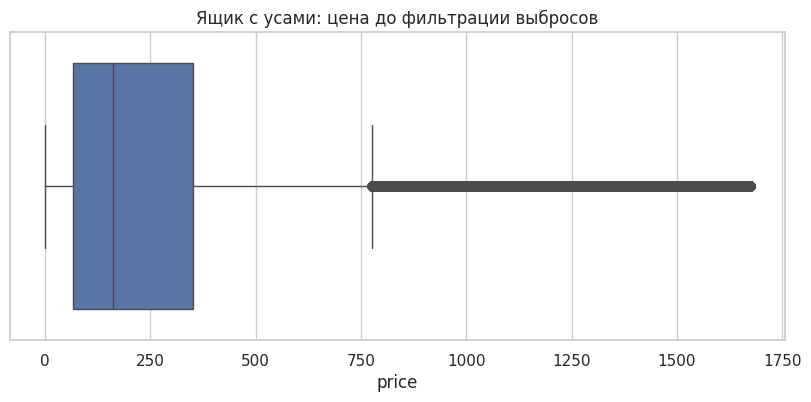

In [6]:
# Квартили цены на полных данных
q1, q3 = df.approxQuantile("price", [0.25, 0.75], 0.01)

# Межквартильный размах
iqr = q3 - q1

# Границы усов по правилу 1.5*IQR
lo_iqr, hi_iqr = q1 - 1.5 * iqr, q3 + 1.5 * iqr

# Число точек за границами усов
n_out = df.filter((col("price") < lo_iqr) | (col("price") > hi_iqr)).count()
total_n = df.count()
print(f"IQR-границы: [{lo_iqr:.1f}; {hi_iqr:.1f}], выбросов: {n_out} ({100*n_out/total_n:.2f}%)")

# Ящик с усами ДО фильтрации: для графика достаточно 1%-й выборки в pandas
prices_before = df.select("price").sample(False, 0.01, seed=42).toPandas()["price"]
plt.figure(figsize=(10, 4))
sns.boxplot(x=prices_before)
plt.title("Ящик с усами: цена до фильтрации выбросов")
plt.show()

In [7]:
# Z-score-проверка: точки дальше 3 СКО от среднего
mean_p, std_p = df.select(mean("price"), stddev("price")).first()

# Считаем фильтром: |price - среднее| / СКО > 3
n_out_z = df.filter(abs(col("price") - mean_p) / std_p > 3).count()
print(f"Среднее = {mean_p:.2f}, СКО = {std_p:.2f}")
print(f"Точек с |z| > 3: {n_out_z} ({100*n_out_z/total_n:.2f}%)")

Среднее = 273.73, СКО = 306.82
Точек с |z| > 3: 2590884 (2.39%)


Осталось строк после IQR-фильтра: 99093454


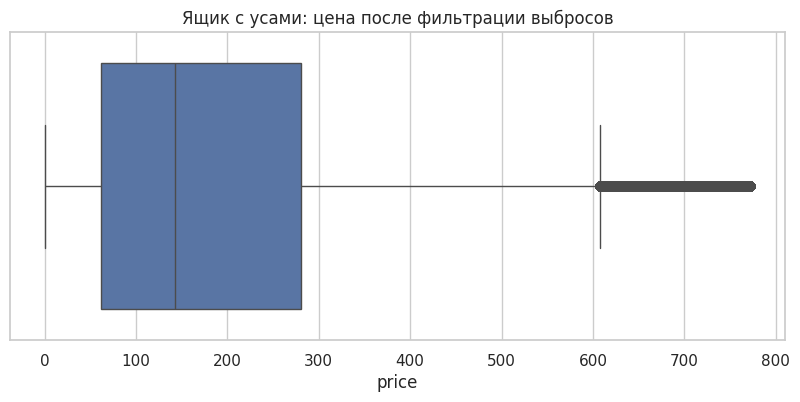

In [8]:
# Фильтруем выбросы цены по IQR-границам (в основной работе - по 99-му перцентилю;
# здесь показываем классический IQR-вариант и сравниваем масштаб)
df_iqr = df.filter((col("price") >= lo_iqr) & (col("price") <= hi_iqr))
print(f"Осталось строк после IQR-фильтра: {df_iqr.count()}")

# Ящик с усами ПОСЛЕ фильтрации: хвост обрезан, распределение компактнее
prices_after = df_iqr.select("price").sample(False, 0.01, seed=42).toPandas()["price"]
plt.figure(figsize=(10, 4))
sns.boxplot(x=prices_after)
plt.title("Ящик с усами: цена после фильтрации выбросов")
plt.show()

## 3. Диаграммы рассеяния и 3D-график (п.6 требований)

/tmp/ipykernel_1834055/1993016948.py:10: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  plt.tight_layout()
/opt/conda-spark-envs/pyspark-env/lib/python3.11/site-packages/IPython/core/pylabtools.py:170: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  fig.canvas.print_figure(bytes_io, **kw)


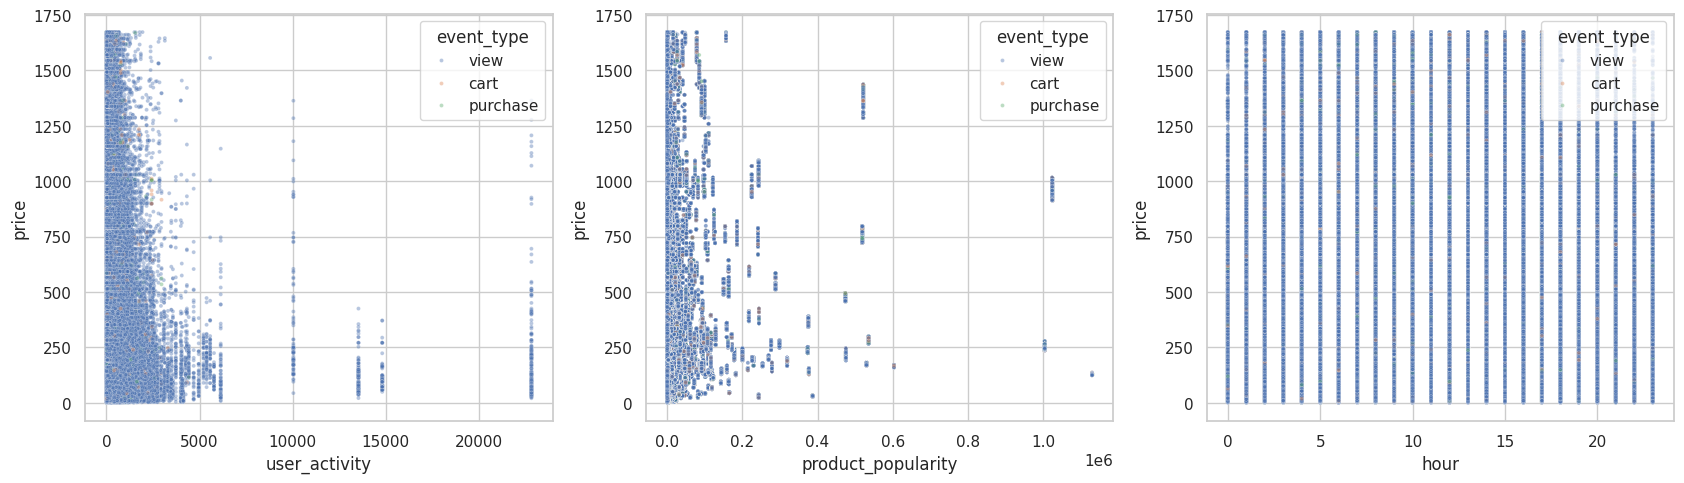

In [9]:
# Выборка 1% с нужными столбцами в pandas
pairs = (df.select("price", "user_activity", "product_popularity", "hour", "event_type")
           .sample(False, 0.01, seed=42).toPandas())

# Три диаграммы рассеяния с цветом по типу события
fig, axes = plt.subplots(1, 3, figsize=(17, 5))
sns.scatterplot(data=pairs, x="user_activity", y="price", hue="event_type", s=8, alpha=0.4, ax=axes[0])
sns.scatterplot(data=pairs, x="product_popularity", y="price", hue="event_type", s=8, alpha=0.4, ax=axes[1])
sns.scatterplot(data=pairs, x="hour", y="price", hue="event_type", s=8, alpha=0.4, ax=axes[2])
plt.tight_layout()
plt.show()

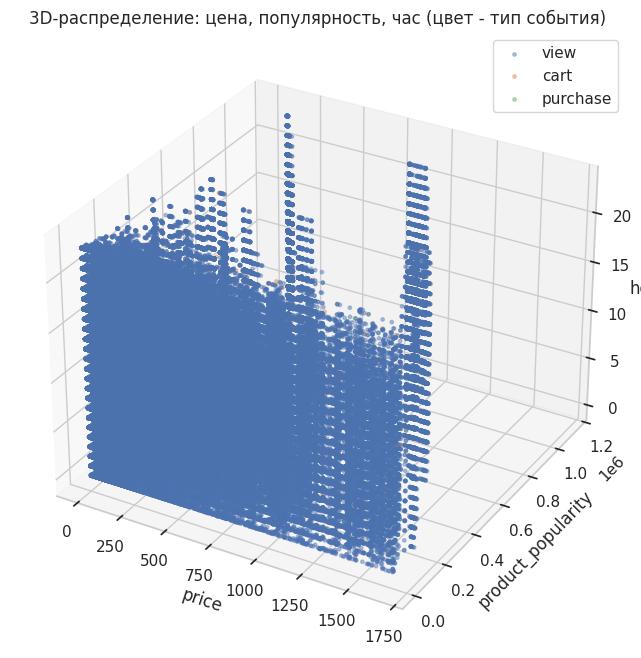

In [10]:
# 3D-график: цена, популярность товара, час; цвет - тип события
fig = plt.figure(figsize=(11, 8))
# Добавляем трехмерные оси
ax = fig.add_subplot(111, projection="3d")
# Каждый тип события - своим цветом
for ev in pairs["event_type"].unique():
    sub = pairs[pairs["event_type"] == ev]
    ax.scatter(sub["price"], sub["product_popularity"], sub["hour"], s=6, alpha=0.4, label=ev)
ax.set_xlabel("price")
ax.set_ylabel("product_popularity")
ax.set_zlabel("hour")
ax.legend()
plt.title("3D-распределение: цена, популярность, час (цвет - тип события)")
plt.show()

## 4. Предобработка текстовых данных (п.7 требований)

Единственный текст в событийном наборе - описание товара: категория + бренд
(`electronics.smartphone` + `samsung`). Очистка: нижний регистр, удаление пунктуации,
удаление стоп-слов. Работаем на 1%-й выборке (текст однотипный, выборка представительна).

In [11]:
# Текстовая выборка 1%: категория, бренд, тип события
text_df = df.select("category_code", "brand", "event_type").sample(False, 0.01, seed=42)

# Описание товара: категория (точки -> пробелы) + бренд, нижний регистр
text_df = text_df.withColumn("item_description",
                             lower(concat(regexp_replace("category_code", "\\.", " "), lit(" "), col("brand"))))

# Шаг очистки 1: оставляем только буквы и пробелы (убираем цифры и пунктуацию)
text_df = text_df.withColumn("text_lower", regexp_replace(col("item_description"), "[^a-z ]", " "))

# Шаг очистки 2: разбиваем на слова
tokenizer = Tokenizer(inputCol="text_lower", outputCol="words")
text_df = tokenizer.transform(text_df)

# Шаг очистки 3: убираем английские стоп-слова встроенным списком Spark ML
stop_remover = StopWordsRemover(inputCol="words", outputCol="text_filtered")
text_df = stop_remover.transform(text_df)

# Сравнение: исходное описание и очищенные слова
text_df.select("item_description", "text_filtered").show(5, truncate=False)

+----------------------------+--------------------------------+
|item_description            |text_filtered                   |
+----------------------------+--------------------------------+
|electronics smartphone apple|[electronics, smartphone, apple]|
|electronics smartphone apple|[electronics, smartphone, apple]|
|electronics smartphone apple|[electronics, smartphone, apple]|
|electronics smartphone apple|[electronics, smartphone, apple]|
|electronics smartphone apple|[electronics, smartphone, apple]|
+----------------------------+--------------------------------+
only showing top 5 rows



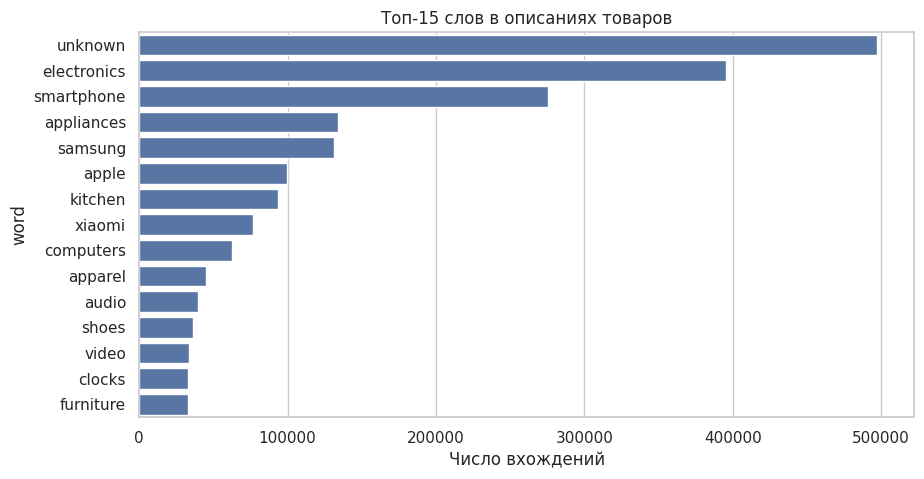

In [12]:
# Топ-15 слов описаний: explode разворачивает массив в строки, groupBy считает вхождения
top_words = (text_df.select(explode("text_filtered").alias("word"))
                     .groupBy("word").count()
                     .orderBy(desc("count")).limit(15).toPandas())

plt.figure(figsize=(10, 5))
sns.barplot(data=top_words, x="count", y="word")
plt.title("Топ-15 слов в описаниях товаров")
plt.xlabel("Число вхождений")
plt.show()

## 5. Кодирование и масштабирование (п.8 требований)

One-Hot кодирование категориальных признаков и стандартизация числовых;
итоговая матрица сохраняется в Parquet в HDFS.

In [13]:
# Выборка 5% для демонстрации кодирования
enc_df = (df.select("price", "hour", "day_of_week", "user_activity", "product_popularity",
                    "category_l1", "event_type")
            .sample(False, 0.05, seed=42))

# Категориальные -> индексы (handleInvalid=keep - незнакомая категория не уронит модель)
enc_indexer = StringIndexer(inputCols=["category_l1", "event_type"],
                            outputCols=["cat_idx", "ev_idx"], handleInvalid="keep")
# Индексы -> One-Hot векторы
enc_encoder = OneHotEncoder(inputCols=["cat_idx", "ev_idx"], outputCols=["cat_ohe", "ev_ohe"])
# Числовые -> один вектор
enc_asm1 = VectorAssembler(inputCols=["price", "hour", "day_of_week",
                                      "user_activity", "product_popularity"],
                           outputCol="num_vec")
# Стандартизация числового вектора (среднее 0, дисперсия 1)
enc_scaler = StandardScaler(inputCol="num_vec", outputCol="num_scaled", withMean=True, withStd=True)
# Все признаки -> итоговый вектор
enc_asm2 = VectorAssembler(inputCols=["num_scaled", "cat_ohe", "ev_ohe"], outputCol="features")

# Конвейер кодирования
enc_pipeline = Pipeline(stages=[enc_indexer, enc_encoder, enc_asm1, enc_scaler, enc_asm2])

# Обучаем и применяем
encoded = enc_pipeline.fit(enc_df).transform(enc_df)

# Итоговые векторы
encoded.select("features").show(3, truncate=False)

+----------------------------------------------------------------------------------------------------------------------------------+
|features                                                                                                                          |
+----------------------------------------------------------------------------------------------------------------------------------+
|(22,[0,1,2,3,4,5,19],[1.1235120927359064,1.08167042429998,-1.5140775378222462,-0.2390269710397953,-0.29538909226703663,1.0,1.0])  |
|(22,[0,1,2,3,4,5,19],[1.0356587226965577,-1.1776409021319993,0.8838067346897182,-0.2898833774531724,-0.29538909226703663,1.0,1.0])|
|(22,[0,1,2,3,4,5,19],[1.122663898298096,1.6464982559079746,-1.5140775378222462,-0.3122601962750583,-0.29538909226703663,1.0,1.0]) |
+----------------------------------------------------------------------------------------------------------------------------------+
only showing top 3 rows



In [14]:
# Сохраняем закодированную выборку в Parquet в HDFS
encoded.write.mode("overwrite").parquet(f"hdfs:///user/{user_name}/korolev/encoded_sample.parquet")
print("Сохранено: encoded_sample.parquet")

Сохранено: encoded_sample.parquet


---
# Дополнение к ЛР2. Иерархическая кластеризация, k-distance, сравнение 3 алгоритмов

## 1. Подготовка: те же признаки и масштабирование, что в основной работе

In [15]:
# Количественные признаки кластеризации (как в основной работе)
cl_features = df.select("price", "hour", "day_of_week", "user_activity", "product_popularity")

# 1%-я выборка (как в основной работе)
cl_features = cl_features.sample(False, 0.01, seed=42).cache()

# Сборка в вектор
cl_asm = VectorAssembler(inputCols=["price", "hour", "day_of_week",
                                    "user_activity", "product_popularity"],
                         outputCol="features")
# Стандартизация
cl_scaler = StandardScaler(inputCol="features", outputCol="scaled_features", withMean=True, withStd=True)

# Конвейер подготовки
cl_prep = Pipeline(stages=[cl_asm, cl_scaler]).fit(cl_features)

# Масштабированные данные
scaled_df = cl_prep.transform(cl_features).cache()

# KMeans с k = 4 (выбран по максимуму силуэта в основной работе)
kmeans_model = KMeans(k=4, seed=42, featuresCol="scaled_features").fit(scaled_df)

# Разметка кластеров
clustered_df = kmeans_model.transform(scaled_df)

26/11/05 22:13:19 WARN InstanceBuilder: Failed to load implementation from:dev.ludovic.netlib.blas.JNIBLAS


## 2. 3D-визуализация кластеров (PCA до 3 компонент)

26/11/05 22:14:08 WARN InstanceBuilder: Failed to load implementation from:dev.ludovic.netlib.lapack.JNILAPACK


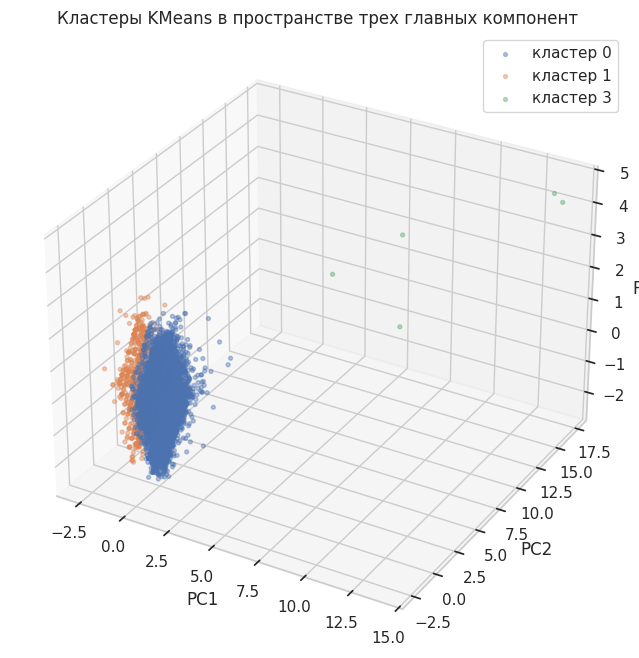

In [16]:
# PCA до 3 главных компонент - для объемной картинки
pca3 = PCA(k=3, inputCol="scaled_features", outputCol="pca3").fit(scaled_df)
pca3_df = pca3.transform(clustered_df)

# Выборка 5000 строк в pandas
pca3_sample = (pca3_df.select(vector_to_array("pca3").alias("v"), "prediction")
                     .sample(False, 0.3, seed=42).limit(5000).toPandas())

# Разбираем вектор на координаты x, y, z
pca3_sample[["x", "y", "z"]] = pd.DataFrame(pca3_sample["v"].tolist(), index=pca3_sample.index)

# 3D-диаграмма рассеяния с цветом по кластеру
fig = plt.figure(figsize=(11, 8))
ax = fig.add_subplot(111, projection="3d")
for cl in sorted(pca3_sample["prediction"].unique()):
    sub = pca3_sample[pca3_sample["prediction"] == cl]
    ax.scatter(sub["x"], sub["y"], sub["z"], s=8, alpha=0.4, label=f"кластер {cl}")
ax.set_xlabel("PC1")
ax.set_ylabel("PC2")
ax.set_zlabel("PC3")
ax.legend()
plt.title("Кластеры KMeans в пространстве трех главных компонент")
plt.show()

## 3. Подвыборка 5000 точек для алгоритмов из sklearn

Иерархическая кластеризация требует матрицу связей O(n²) - на миллионе строк это
невозможно; DBSCAN и метрики сравнения считаем на той же подвыборке, чтобы все три
алгоритма сравнивались на одинаковых данных.

In [17]:
# Подвыборка 5000 масштабированных векторов в numpy
dbscan_sample = scaled_df.select("scaled_features").limit(5000)
sub_vectors = np.array([r["scaled_features"].toArray() for r in dbscan_sample.collect()])
print(f"Форма массива: {sub_vectors.shape}")

Форма массива: (5000, 5)


## 4. DBSCAN: k-distance график для подбора eps

Стандартный метод выбора eps: расстояния до k-го соседа, отсортированные по возрастанию;
«излом» кривой - граница плотных областей.

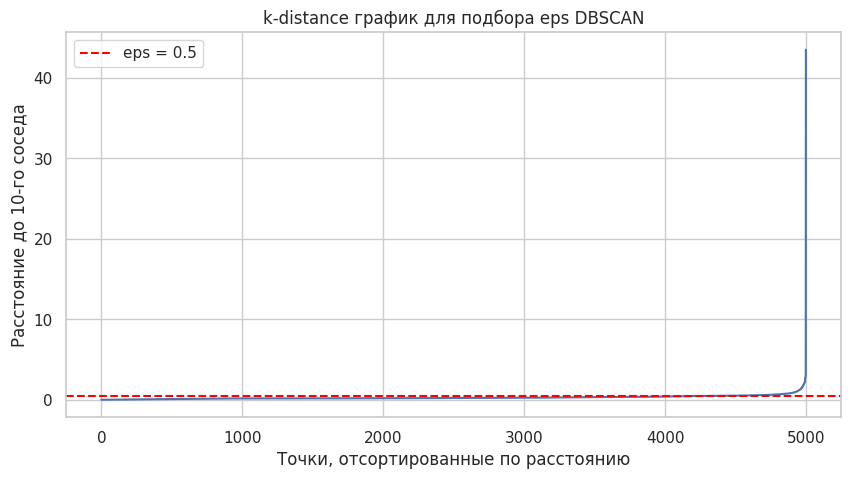

DBSCAN: кластеров = 4, шум = 5.3%


In [18]:
# Расстояния до 10-го ближайшего соседа каждой точки
nbrs = NearestNeighbors(n_neighbors=10).fit(sub_vectors)
dist10, _ = nbrs.kneighbors(sub_vectors)

# Сортируем расстояния 10-го соседа по возрастанию
kdist = np.sort(dist10[:, -1])

# График: излом - кандидат на eps (красная линия - значение из основной работы)
plt.figure(figsize=(10, 5))
plt.plot(kdist)
plt.axhline(0.5, color="red", linestyle="--", label="eps = 0.5")
plt.xlabel("Точки, отсортированные по расстоянию")
plt.ylabel("Расстояние до 10-го соседа")
plt.title("k-distance график для подбора eps DBSCAN")
plt.legend()
plt.show()

# DBSCAN с eps=0.5 (обоснован k-distance графиком и перебором в основной работе)
db_labels = DBSCAN(eps=0.5, min_samples=10).fit_predict(sub_vectors)
print(f"DBSCAN: кластеров = {len(set(db_labels)) - (1 if -1 in db_labels else 0)}, "
      f"шум = {(db_labels == -1).mean():.1%}")

## 5. Иерархическая кластеризация: дендрограмма и порог отсечения

Порог отсечения по скачку расстояний: 65.99


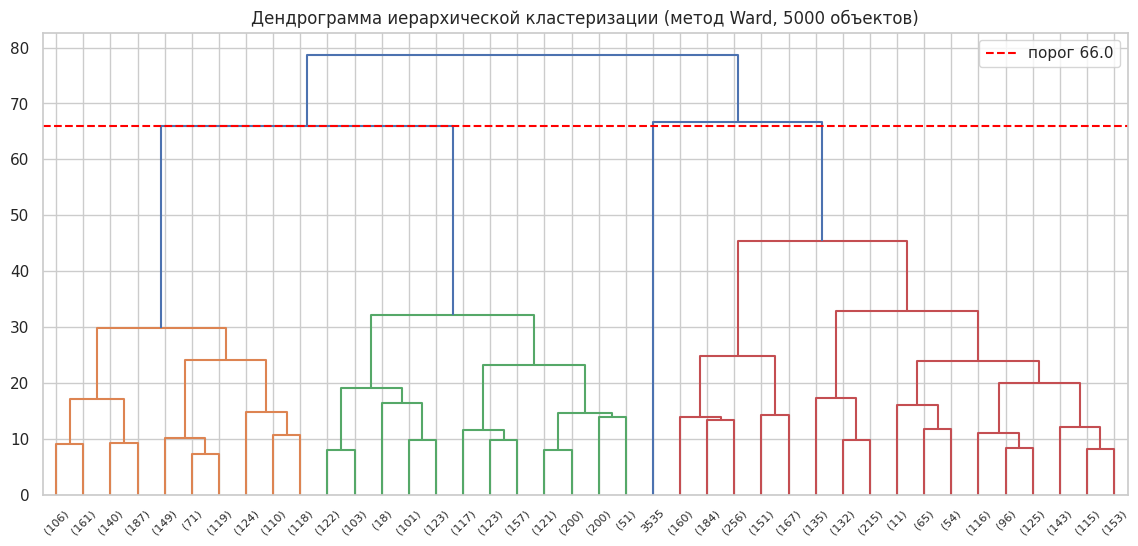

Число кластеров иерархического метода: 3


In [19]:
# Матрица связей методом Уорда (минимизация дисперсии внутри кластеров)
Z = linkage(sub_vectors, method="ward")

# Высоты объединений кластеров
heights = Z[:, 2]

# Самый крупный скачок высоты - естественный "разрыв" между кластерами
jumps = heights[1:] - heights[:-1]
cut_height = heights[int(np.argmax(jumps)) + 1]
print(f"Порог отсечения по скачку расстояний: {cut_height:.2f}")

# Дендрограмма (обрезана до 40 листьев для читаемости; линия - порог)
plt.figure(figsize=(14, 6))
dendrogram(Z, truncate_mode="lastp", p=40, color_threshold=cut_height)
plt.axhline(cut_height, color="red", linestyle="--", label=f"порог {cut_height:.1f}")
plt.title("Дендрограмма иерархической кластеризации (метод Ward, 5000 объектов)")
plt.legend()
plt.show()

# Разрезаем дерево по порогу
hier_labels = fcluster(Z, t=cut_height, criterion="distance")
print(f"Число кластеров иерархического метода: {len(set(hier_labels))}")

## 6. Сравнение трех алгоритмов по внутренним метрикам

Все метрики на одной подвыборке: силуэт (вверх), Calinski-Harabasz (вверх),
Davies-Bouldin (вниз). KMeans на подвыборке обучен заново с тем же k = 4.

In [20]:
# KMeans sklearn на той же подвыборке (k = 4)
km_labels = SkKMeans(n_clusters=4, n_init=10, random_state=42).fit_predict(sub_vectors)

# Строки таблицы сравнения
rows = []
for name, labels in [("KMeans (k=4)", km_labels),
                     ("Иерархическая (Ward)", hier_labels),
                     ("DBSCAN (eps=0.5)", db_labels)]:
    # Точки шума DBSCAN (метка -1) в метрики не включаем - это не кластер
    mask = labels != -1
    n_cl = len(set(labels[mask]))
    if n_cl > 1:
        sil = silhouette_score(sub_vectors[mask], labels[mask])
        ch = calinski_harabasz_score(sub_vectors[mask], labels[mask])
        db = davies_bouldin_score(sub_vectors[mask], labels[mask])
    else:
        sil, ch, db = float("nan"), float("nan"), float("nan")
    rows.append([name, round(sil, 3), round(ch, 1), round(db, 3), n_cl])

# Итоговая таблица сравнения трех алгоритмов
compare_df = pd.DataFrame(rows, columns=["Метод", "Силуэт (вверх)", "Calinski-Harabasz (вверх)",
                                         "Davies-Bouldin (вниз)", "Кластеров"])
compare_df

,Метод,Силуэт (вверх),Calinski-Harabasz (вверх),Davies-Bouldin (вниз),Кластеров
0,KMeans (k=4),0.282,2000.3,0.875,4
1,Иерархическая (Ward),0.220,1320.5,1.127,3
2,DBSCAN (eps=0.5),-0.046,123.6,2.090,4


## 7. Портреты кластеров KMeans: чем сегменты отличаются статистически

In [21]:
# Средние исходных признаков по кластерам KMeans (на полной 1%-й выборке)
profile = (clustered_df.groupBy("prediction")
           .avg("price", "hour", "day_of_week", "user_activity", "product_popularity")
           .orderBy("prediction")
           .toPandas())

# Размеры кластеров
sizes = clustered_df.groupBy("prediction").count().orderBy("prediction").toPandas()

# Профиль + размер в одну таблицу
profile = profile.merge(sizes, on="prediction")
profile.columns = ["кластер", "цена", "час", "день", "активность", "популярность", "размер"]
profile

,кластер,цена,час,день,активность,популярность,размер
0,0,161.970902,11.237449,4.149635,157.254904,34527.802067,873454
1,1,894.867031,11.499211,4.192481,135.613876,71904.125454,146357
2,2,383.045415,10.944542,4.190304,88.291621,792828.671529,62931
3,3,193.401780,11.043261,4.036606,16470.820300,61204.113145,601


---
# Дополнение к ЛР3. Сравнение моделей регрессии, подбор гиперпараметров, TF-IDF, ансамбль

## 1. Подготовка данных (как в основной работе: 5% выборка, топ-20 брендов, 80/20)

In [22]:
# Признаки регрессии: как в основной работе + текстовые поля для TF-IDF эксперимента
reg_df = df.select("price", "category_l1", "brand", "category_code",
                   "hour", "day_of_week", "user_activity", "product_popularity")

# 5%-я выборка (seed=42 - как в основной работе)
reg_df = reg_df.sample(False, 0.05, seed=42).cache()

# Топ-20 брендов по числу событий
top_brands = [r["brand"] for r in reg_df.groupBy("brand").count()
              .orderBy(desc("count")).limit(20).collect()]

# Бренды вне топ-20 -> "other" (тысячи редких категорий не нужны)
reg_df = reg_df.withColumn("brand_top",
                           when(col("brand").isin(top_brands), col("brand")).otherwise(lit("other")))

# Разделение 80/20 (seed=42)
reg_train, reg_test = reg_df.randomSplit([0.8, 0.2], seed=42)
reg_train = reg_train.cache()
reg_test = reg_test.cache()

print(f"Train: {reg_train.count()}, Test: {reg_test.count()}")

Train: 4334583, Test: 1085846


## 2. Обучение четырех моделей и сводная таблица метрик

Линейная модель получает One-Hot кодирование и стандартизацию (ей нужны независимые
признаки одного масштаба); древовидным моделям достаточно индексов категорий -
деревья сами ищут разбиения и нечувствительны к масштабу.

In [23]:
# Общие списки признаков
reg_cat = ["category_l1", "brand_top"]
reg_num = ["hour", "day_of_week", "user_activity", "product_popularity"]

# Конвейер ЛИНЕЙНОЙ модели: индексы -> One-Hot -> сборка -> стандартизация -> модель
lin_indexer = StringIndexer(inputCols=reg_cat, outputCols=["cat_l1_ix", "brand_ix"], handleInvalid="keep")
lin_encoder = OneHotEncoder(inputCols=["cat_l1_ix", "brand_ix"], outputCols=["cat_l1_ohe", "brand_ohe"])
lin_asm = VectorAssembler(inputCols=reg_num + ["cat_l1_ohe", "brand_ohe"], outputCol="raw_features")
lin_scaler = StandardScaler(inputCol="raw_features", outputCol="features", withMean=True, withStd=True)
lin_lr = LinearRegression(featuresCol="features", labelCol="price", regParam=0.01)
lin_pipeline = Pipeline(stages=[lin_indexer, lin_encoder, lin_asm, lin_scaler, lin_lr])

# Конвейер ДЕРЕВЬЯ: индексы -> сборка -> модель
tree_indexer = StringIndexer(inputCols=reg_cat, outputCols=["t_cat_ix", "t_brand_ix"], handleInvalid="keep")
tree_asm = VectorAssembler(inputCols=reg_num + ["t_cat_ix", "t_brand_ix"], outputCol="features")
dt_model = DecisionTreeRegressor(featuresCol="features", labelCol="price", maxDepth=7, seed=42)
dt_pipeline = Pipeline(stages=[tree_indexer, tree_asm, dt_model])

# СЛУЧАЙНЫЙ ЛЕС: 20 несмещенных деревьев
rf_model = RandomForestRegressor(featuresCol="features", labelCol="price",
                                 numTrees=20, maxDepth=7, seed=42)
rf_pipeline = Pipeline(stages=[tree_indexer, tree_asm, rf_model])

# ГРАДИЕНТНЫЙ БУСТИНГ: 20 деревьев последовательно исправляют ошибки друг друга
gb_model = GBTRegressor(featuresCol="features", labelCol="price",
                        maxIter=20, maxDepth=5, stepSize=0.1, seed=42)
gb_pipeline = Pipeline(stages=[tree_indexer, tree_asm, gb_model])

# Обучаем все четыре модели
lin_fit = lin_pipeline.fit(reg_train)
dt_fit = dt_pipeline.fit(reg_train)
rf_fit = rf_pipeline.fit(reg_train)
gb_fit = gb_pipeline.fit(reg_train)
print("Все модели обучены")

Все модели обучены


In [24]:
# Оценщики метрик регрессии: RMSE, MAE, R2 (label - цена)
ev_rmse = RegressionEvaluator(labelCol="price", predictionCol="prediction", metricName="rmse")
ev_mae = RegressionEvaluator(labelCol="price", predictionCol="prediction", metricName="mae")
ev_r2 = RegressionEvaluator(labelCol="price", predictionCol="prediction", metricName="r2")

# Сводная таблица метрик четырех моделей на тесте
rows = []
for name, model in [("Линейная", lin_fit), ("Дерево", dt_fit),
                    ("Случайный лес", rf_fit), ("Бустинг", gb_fit)]:
    # Предсказания модели на тесте
    pred = model.transform(reg_test)
    rows.append([name,
                 round(ev_rmse.evaluate(pred), 2),
                 round(ev_mae.evaluate(pred), 2),
                 round(ev_r2.evaluate(pred), 3)])

reg_compare = pd.DataFrame(rows, columns=["Модель", "RMSE (вниз)", "MAE (вниз)", "R2 (вверх)"])
reg_compare

,Модель,RMSE (вниз),MAE (вниз),R2 (вверх)
0,Линейная,240.28,161.27,0.387
1,Дерево,231.36,155.49,0.431
2,Случайный лес,233.59,157.31,0.420
3,Бустинг,228.68,152.70,0.445


## 3. Подбор гиперпараметров лучшей модели (аналог GridSearch)

TrainValidationSplit - аналог GridSearchCV в Spark: перебор сетки параметров
с одной валидационной выборкой (быстрее кросс-валидации). Сетка небольшая -
полный перебор бустинга на кластере долог.

In [25]:
# Сетка гиперпараметров бустинга: 2 x 2 = 4 комбинации
gb_grid = (ParamGridBuilder()
           .addGrid(gb_model.maxDepth, [3, 5])      # глубина деревьев
           .addGrid(gb_model.maxIter, [10, 20])     # число деревьев
           .build())

# TrainValidationSplit: 80% обучение / 20% валидация, оптимизация по RMSE
tvs = TrainValidationSplit(estimator=gb_pipeline,
                           estimatorParamMaps=gb_grid,
                           evaluator=RegressionEvaluator(labelCol="price",
                                                         predictionCol="prediction",
                                                         metricName="rmse"),
                           trainRatio=0.8, seed=42, parallelism=2)

# Обучаем с перебором сетки (занимает время: 4 обучения бустинга)
tvs_model = tvs.fit(reg_train)

# Лучшие гиперпараметры (последняя стадия конвейера - сам бустинг)
best_gb = tvs_model.bestModel.stages[-1]
print(f"Лучшие параметры бустинга: maxDepth={best_gb.getMaxDepth()}, maxIter={best_gb.getMaxIter()}")

# Метрики настроенной модели на тесте
gb_tuned_pred = tvs_model.transform(reg_test)
print(f"RMSE tuned: {ev_rmse.evaluate(gb_tuned_pred):.2f} "
      f"(до настройки: {reg_compare.loc[reg_compare['Модель']=='Бустинг','RMSE (вниз)'].iloc[0]})")

Лучшие параметры бустинга: maxDepth=5, maxIter=20


RMSE tuned: 228.68 (до настройки: 228.68)


## 4. График "фактические vs предсказанные значения" лучшей модели

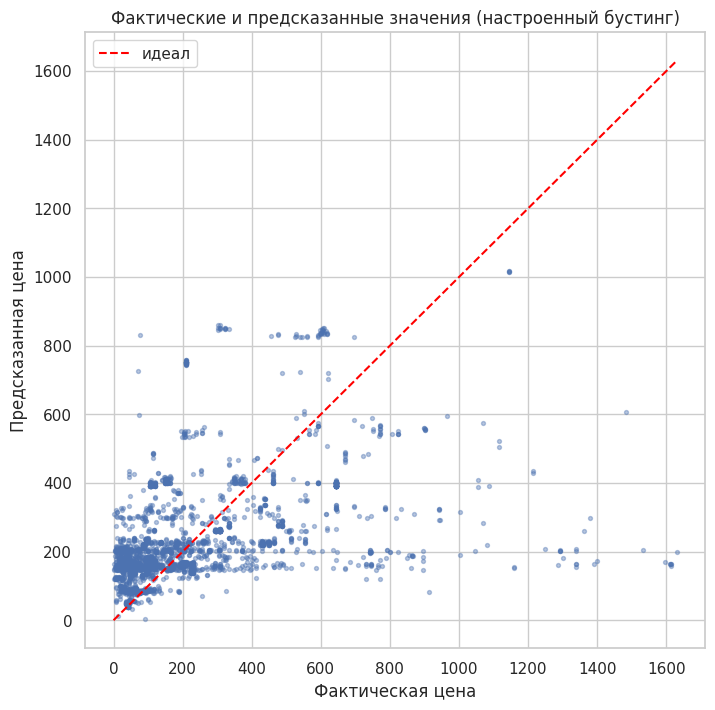

In [26]:
# Выборка 3000 строк предсказаний лучшей модели в pandas
act_pred = (tvs_model.transform(reg_test)
            .select("price", "prediction")
            .sample(False, 0.05, seed=42).limit(3000).toPandas())

# Диагональ - идеальные предсказания; чем плотнее точки к ней, тем лучше
plt.figure(figsize=(8, 8))
plt.scatter(act_pred["price"], act_pred["prediction"], s=8, alpha=0.4)
max_val = max(act_pred["price"].max(), act_pred["prediction"].max())
plt.plot([0, max_val], [0, max_val], color="red", linestyle="--", label="идеал")
plt.xlabel("Фактическая цена")
plt.ylabel("Предсказанная цена")
plt.title("Фактические и предсказанные значения (настроенный бустинг)")
plt.legend()
plt.show()

## 5. Эксперимент 1: табличные признаки + TF-IDF текста описания

Гипотеза: описание товара (категория + бренд) может нести информацию о цене сверх
категориальных признаков. Строим TF-IDF по токенам описания и добавляем к табличным.

In [27]:
# Конвейер TF-IDF: очистка текста -> токены -> стоп-слова -> частоты -> вес IDF
tfidf_df = reg_df

# Описание товара: категория без точек + бренд, нижний регистр
tfidf_df = tfidf_df.withColumn("item_description",
                               lower(concat(regexp_replace("category_code", "\\.", " "),
                                           lit(" "), col("brand"))))
# Убираем не-буквы
tfidf_df = tfidf_df.withColumn("text_lower", regexp_replace(col("item_description"), "[^a-z ]", " "))

# Токенизация и стоп-слова
tf_tokenizer = Tokenizer(inputCol="text_lower", outputCol="words")
tf_remover = StopWordsRemover(inputCol="words", outputCol="text_filtered")
# Частотные векторы (_hashing - быстрый подсчет по 512 ячейкам)
tf_hashing = HashingTF(inputCol="text_filtered", outputCol="raw_tf", numFeatures=512)
# IDF - понижение веса частых слов
tf_idf = IDF(inputCol="raw_tf", outputCol="tfidf_features")

# Разделение то же 80/20 (seed=42)
tf_train, tf_test = tfidf_df.randomSplit([0.8, 0.2], seed=42)

# Текстовый подконвейер
text_pipe = Pipeline(stages=[tf_tokenizer, tf_remover, tf_hashing, tf_idf])
text_fit = text_pipe.fit(tf_train)
tf_train2 = text_fit.transform(tf_train).cache()
tf_test2 = text_fit.transform(tf_test).cache()

# Индексы категорий (как у деревьев)
tf_indexer = StringIndexer(inputCols=reg_cat, outputCols=["t_cat_ix", "t_brand_ix"], handleInvalid="keep")
tf_asm = VectorAssembler(inputCols=reg_num + ["t_cat_ix", "t_brand_ix", "tfidf_features"],
                         outputCol="features")
# Бустинг с лучшими найденными параметрами
tf_gb = GBTRegressor(featuresCol="features", labelCol="price",
                     maxIter=best_gb.getMaxIter(), maxDepth=best_gb.getMaxDepth(),
                     stepSize=0.1, seed=42)
tf_pipeline = Pipeline(stages=[tf_indexer, tf_asm, tf_gb])

# Обучаем бустинг на табличных + TF-IDF признаках
tf_model = tf_pipeline.fit(tf_train2)

# Метрика на тесте
tf_pred = tf_model.transform(tf_test2)
print(f"RMSE с TF-IDF: {ev_rmse.evaluate(tf_pred):.2f}")

RMSE с TF-IDF: 202.04


## 6. Эксперимент 2: взвешенное ансамблирование

Среднее предсказаний трех моделей с весами 0.5 (бустинг) + 0.3 (лес) + 0.2 (линейная):
сильной модели - больший вес.

In [31]:
# Предсказания всех моделей на одном датафрейме: последовательно трансформируем тест.
# После каждой модели удаляем ВСЕ служебные столбцы ее конвейера
# (features, индексы категорий, One-Hot векторы) - иначе следующий конвейер
# упадет на конфликте имен
ens = lin_fit.transform(reg_test)     .drop("cat_l1_ix", "brand_ix", "cat_l1_ohe", "brand_ohe", "raw_features", "features")     .withColumnRenamed("prediction", "pred_lr")
ens = rf_fit.transform(ens)     .drop("t_cat_ix", "t_brand_ix", "features")     .withColumnRenamed("prediction", "pred_rf")
ens = tvs_model.transform(ens)     .drop("t_cat_ix", "t_brand_ix", "features")     .withColumnRenamed("prediction", "pred_gb")

# Взвешенная сумма: 0.5*бустинг + 0.3*лес + 0.2*линейная
ens = ens.withColumn("prediction", 0.5 * col("pred_gb") + 0.3 * col("pred_rf") + 0.2 * col("pred_lr"))

# Метрики ансамбля на тесте
print(f"RMSE ансамбля: {ev_rmse.evaluate(ens):.2f}")
print(f"R2 ансамбля:   {ev_r2.evaluate(ens):.3f}")

RMSE ансамбля: 231.07


R2 ансамбля:   0.433


**Выводы по дополнению ЛР3:** сравнение моделей, эффект настройки гиперпараметров,
вклад TF-IDF признаков и ансамблирования фиксируются таблицей выше (числа подставятся при запуске).

---
# Дополнение к ЛР4. Сравнение моделей классификации, голосование, важность признаков

## 1. Подготовка данных (как в основной работе: 2% выборка, is_purchase, oversampling)

In [32]:
# Целевая: факт покупки; признаки - как в основной работе
cls_df = df.select("event_type", "price", "hour", "day_of_week",
                   "user_activity", "product_popularity", "category_l1", "brand")

# Бинарная цель: 1 = покупка, 0 = остальное
cls_df = cls_df.withColumn("is_purchase",
                           when(col("event_type") == "purchase", 1).otherwise(0).cast("int"))

# 2%-я выборка (seed=42 - как в основной работе)
cls_df = cls_df.sample(False, 0.02, seed=42)

# Топ-20 брендов -> brand_top
top_brands_c = [r["brand"] for r in cls_df.groupBy("brand").count()
                .orderBy(desc("count")).limit(20).collect()]
cls_df = cls_df.withColumn("brand_top",
                           when(col("brand").isin(top_brands_c), col("brand")).otherwise(lit("other")))

# Разделение 80/20 (seed=42)
cls_train, cls_test = cls_df.randomSplit([0.8, 0.2], seed=42)
cls_train = cls_train.cache()
cls_test = cls_test.cache()
print(f"Train: {cls_train.count()}, Test: {cls_test.count()}")

Train: 1733599, Test: 432988


In [34]:
# array - функция сборки массива из значений (для дублирования строк)
from pyspark.sql.functions import array

# Oversampling положительного класса в ОБУЧАЮЩЕЙ выборке (как в основной работе):
# покупки дублируем, пока классы не сравняются - иначе модели выучат "всегда 0"
pos = cls_train.filter(col("is_purchase") == 1)
neg = cls_train.filter(col("is_purchase") == 0)
repeat_times = int(neg.count() / pos.count())
pos_rep = pos.withColumn("dummy", explode(array([lit(x) for x in range(repeat_times)]))).drop("dummy")
cls_train_bal = pos_rep.unionAll(neg.select(pos.columns)).cache()
cls_train_bal.groupBy("is_purchase").count().show()

+-----------+-------+
|is_purchase|  count|
+-----------+-------+
|          1|1705080|
|          0|1707367|
+-----------+-------+



## 2. Четыре модели: логрегрессия, дерево, лес, бустинг

Логистической регрессии нужны One-Hot и стандартизация (линейная модель);
деревьям достаточно индексов категорий.

In [35]:
# Списки признаков классификации
cls_cat = ["category_l1", "brand_top"]
cls_num = ["price", "hour", "day_of_week", "user_activity", "product_popularity"]

# Импортируем array для дублирования строк
from pyspark.sql.functions import array

# Конвейер ЛОГРЕССИИ: One-Hot + стандартизация
log_indexer = StringIndexer(inputCols=cls_cat, outputCols=["l_cat_ix", "l_brand_ix"], handleInvalid="keep")
log_encoder = OneHotEncoder(inputCols=["l_cat_ix", "l_brand_ix"], outputCols=["l_cat_ohe", "l_brand_ohe"])
log_asm = VectorAssembler(inputCols=cls_num + ["l_cat_ohe", "l_brand_ohe"], outputCol="raw_features")
log_scaler = StandardScaler(inputCol="raw_features", outputCol="features", withMean=True, withStd=True)
log_model = LogisticRegression(featuresCol="features", labelCol="is_purchase", maxIter=20)
log_pipeline = Pipeline(stages=[log_indexer, log_encoder, log_asm, log_scaler, log_model])

# Конвейер ДЕРЕВЯ: индексы -> сборка -> модель
c_indexer = StringIndexer(inputCols=cls_cat, outputCols=["c_cat_ix", "c_brand_ix"], handleInvalid="keep")
c_asm = VectorAssembler(inputCols=cls_num + ["c_cat_ix", "c_brand_ix"], outputCol="features")
cdt_model = DecisionTreeClassifier(featuresCol="features", labelCol="is_purchase", maxDepth=7, seed=42)
cdt_pipeline = Pipeline(stages=[c_indexer, c_asm, cdt_model])

# СЛУЧАЙНЫЙ ЛЕС
crf_model = RandomForestClassifier(featuresCol="features", labelCol="is_purchase",
                                   numTrees=20, maxDepth=7, seed=42)
crf_pipeline = Pipeline(stages=[c_indexer, c_asm, crf_model])

# БУСТИНГ (та же конфигурация, что в основной работе)
cgb_model = GBTClassifier(featuresCol="features", labelCol="is_purchase",
                          maxIter=20, maxDepth=5, stepSize=0.1, seed=42)
cgb_pipeline = Pipeline(stages=[c_indexer, c_asm, cgb_model])

# Обучаем все четыре модели на сбалансированной выборке
log_fit = log_pipeline.fit(cls_train_bal)
cdt_fit = cdt_pipeline.fit(cls_train_bal)
crf_fit = crf_pipeline.fit(cls_train_bal)
cgb_fit = cgb_pipeline.fit(cls_train_bal)
print("Все модели обучены")

Все модели обучены


## 3. Сводная таблица метрик на тесте (естественный дисбаланс 1:65)

In [36]:
# Функция метрик по предсказаниям: Precision, Recall, F1, AUC
def cls_metrics(pred):
    # TP/FP/FN/TN считаем фильтрами
    tp = pred.filter((col("is_purchase") == 1) & (col("prediction") == 1)).count()
    fp = pred.filter((col("is_purchase") == 0) & (col("prediction") == 1)).count()
    fn = pred.filter((col("is_purchase") == 1) & (col("prediction") == 0)).count()
    precision = tp / (tp + fp) if tp + fp > 0 else 0.0
    recall = tp / (tp + fn) if tp + fn > 0 else 0.0
    f1 = 2 * precision * recall / (precision + recall) if precision + recall > 0 else 0.0
    auc = BinaryClassificationEvaluator(labelCol="is_purchase", rawPredictionCol="probability").evaluate(pred)
    return precision, recall, f1, auc

# Метрики всех моделей на тесте
rows = []
for name, model in [("Логрегрессия", log_fit), ("Дерево", cdt_fit),
                    ("Случайный лес", crf_fit), ("Бустинг", cgb_fit)]:
    pred = model.transform(cls_test)
    p, r, f1, a = cls_metrics(pred)
    rows.append([name, round(p, 3), round(r, 3), round(f1, 3), round(a, 3)])

cls_compare = pd.DataFrame(rows, columns=["Модель", "Precision", "Recall", "F1", "ROC-AUC"])
cls_compare

,Модель,Precision,Recall,F1,ROC-AUC
0,Логрегрессия,0.027,0.572,0.052,0.675
1,Дерево,0.027,0.625,0.053,0.675
2,Случайный лес,0.029,0.595,0.056,0.693
3,Бустинг,0.028,0.632,0.054,0.699


## 4. Голосование (soft voting): среднее вероятностей трех моделей

In [40]:
# Вероятности покупки каждой модели на одном датафрейме.
# Порядок для каждой модели: трансформация -> чистка служебных столбцов конвейера ->
# сохранение нужной вероятности в отдельный столбец -> удаление служебных
# rawPrediction/probability/prediction, чтобы следующая модель не столкнулась с ними
vote = log_fit.transform(cls_test)
vote = vote.drop("l_cat_ix", "l_brand_ix", "l_cat_ohe", "l_brand_ohe", "raw_features", "features")
vote = vote.withColumnRenamed("prediction", "p_log")
vote = vote.withColumn("prob_log", vector_to_array("probability").getItem(1))
vote = vote.drop("rawPrediction", "probability")

vote = crf_fit.transform(vote)
vote = vote.drop("c_cat_ix", "c_brand_ix", "features", "prediction")
vote = vote.withColumn("prob_rf", vector_to_array("probability").getItem(1))
vote = vote.drop("rawPrediction", "probability")

vote = cgb_fit.transform(vote)
vote = vote.drop("c_cat_ix", "c_brand_ix", "features")
vote = vote.withColumn("prob_gb", vector_to_array("probability").getItem(1))

# Итоговая вероятность - среднее трех; класс 1, если она >= 0.5
vote = vote.withColumn("prob_vote", (col("prob_log") + col("prob_rf") + col("prob_gb")) / 3)
vote = vote.withColumn("prediction", when(col("prob_vote") >= 0.5, 1).otherwise(0))

# Метрики голосования
p, r, f1, a = cls_metrics(vote)
print(f"Голосование: Precision={p:.3f}, Recall={r:.3f}, F1={f1:.3f}, AUC={a:.3f}")

Голосование: Precision=0.030, Recall=0.606, F1=0.057, AUC=0.699


## 5. Матрица ошибок лучшей модели

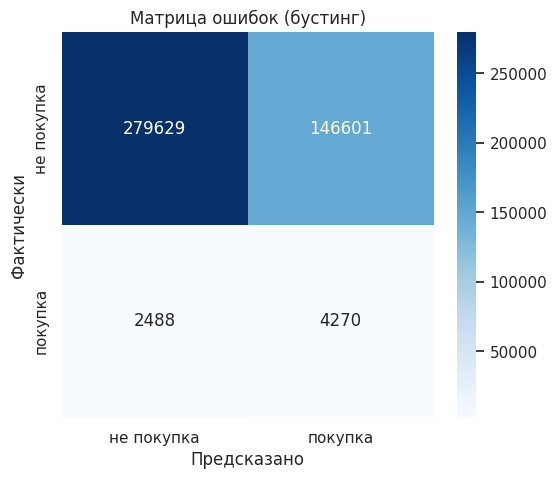

In [41]:
# Предсказания бустинга в pandas (метка и класс)
gb_pred_pd = cgb_fit.transform(cls_test).select("is_purchase", "prediction").toPandas()

# Матрица ошибок 2x2 sklearn
cm = confusion_matrix(gb_pred_pd["is_purchase"], gb_pred_pd["prediction"])

# Тепловая карта матрицы ошибок
plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=["не покупка", "покупка"], yticklabels=["не покупка", "покупка"])
plt.xlabel("Предсказано")
plt.ylabel("Фактически")
plt.title("Матрица ошибок (бустинг)")
plt.show()

## 6. ROC-кривые всех моделей

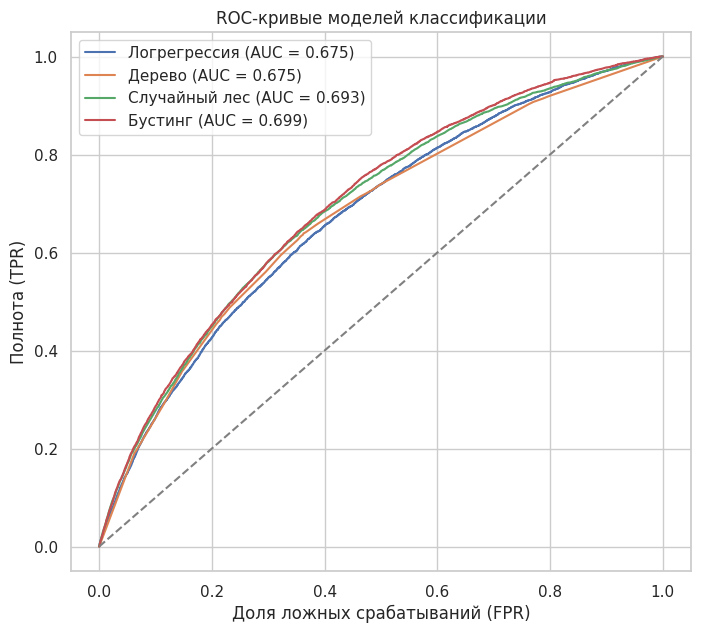

In [42]:
# ROC-кривые: вероятность покупки + метка -> pandas -> sklearn
plt.figure(figsize=(8, 7))
for name, model, prob_col in [("Логрегрессия", log_fit, None),
                              ("Дерево", cdt_fit, None),
                              ("Случайный лес", crf_fit, None),
                              ("Бустинг", cgb_fit, None)]:
    # Вероятность класса 1 и метка
    pr = model.transform(cls_test).select(vector_to_array("probability").getItem(1).alias("p"),
                                          "is_purchase").toPandas()
    # ROC-кривая sklearn: порог перебирается автоматически
    fpr, tpr, _ = roc_curve(pr["is_purchase"], pr["p"])
    plt.plot(fpr, tpr, label=f"{name} (AUC = {auc(fpr, tpr):.3f})")

# Диагональ - случайная модель
plt.plot([0, 1], [0, 1], color="gray", linestyle="--")
plt.xlabel("Доля ложных срабатываний (FPR)")
plt.ylabel("Полнота (TPR)")
plt.title("ROC-кривые моделей классификации")
plt.legend()
plt.show()

## 7. Важность признаков бустинга

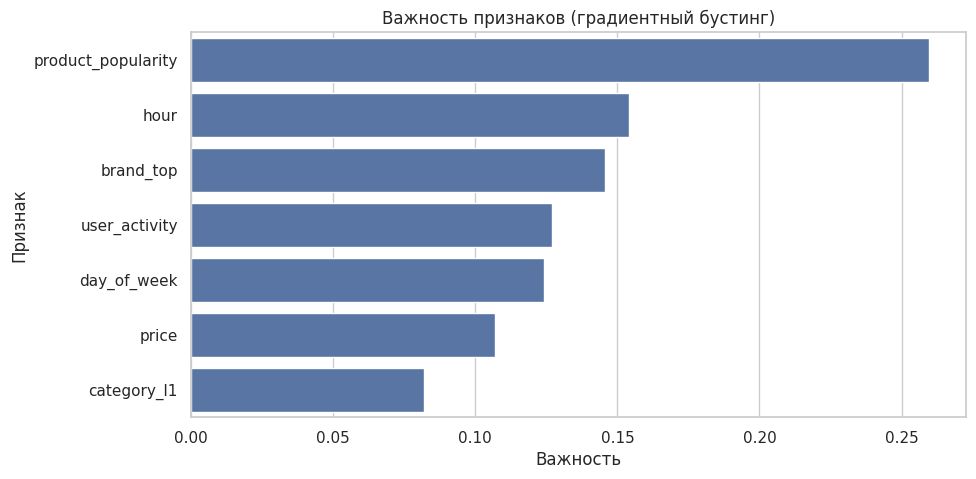

,Признак,Важность
4,product_popularity,0.259738
1,hour,0.154207
6,brand_top,0.145571
3,user_activity,0.127113
2,day_of_week,0.124298
0,price,0.107020
5,category_l1,0.082053


In [43]:
# Важности признаков из модели (последняя стадия конвейера)
importances = cgb_fit.stages[-1].featureImportances.toArray()

# Имена признаков = порядок сборки вектора: числовые + индексы категорий
feat_names = cls_num + ["category_l1", "brand_top"]

# Таблица и график важностей
imp_df = pd.DataFrame({"Признак": feat_names, "Важность": importances}
                      ).sort_values("Важность", ascending=False)
plt.figure(figsize=(10, 5))
sns.barplot(data=imp_df, x="Важность", y="Признак")
plt.title("Важность признаков (градиентный бустинг)")
plt.show()
imp_df

## 8. Устойчивость к переобучению: разрыв train/test

In [44]:
# F1 каждой модели на ОБУЧАЮЩЕЙ и ТЕСТОВОЙ выборках: большой разрыв = переобучениe
rows = []
for name, model in [("Логрегрессия", log_fit), ("Дерево", cdt_fit),
                    ("Случайный лес", crf_fit), ("Бустинг", cgb_fit)]:
    f1_test = cls_metrics(model.transform(cls_test))[2]
    f1_train = cls_metrics(model.transform(cls_train))[2]
    rows.append([name, round(f1_train, 3), round(f1_test, 3), round(f1_train - f1_test, 3)])

overfit_df = pd.DataFrame(rows, columns=["Модель", "F1 train", "F1 test", "Разрыв"])
overfit_df

,Модель,F1 train,F1 test,Разрыв
0,Логрегрессия,0.050,0.052,-0.003
1,Дерево,0.052,0.053,-0.001
2,Случайный лес,0.055,0.056,-0.001
3,Бустинг,0.054,0.054,-0.000


## 9. Инсайты: какие признаки склоняют модель к классу «покупка»

In [45]:
# Средние значения признаков по классам (на тесте, естественное соотношение)
class_means = (cls_test.groupBy("is_purchase")
               .avg("price", "hour", "day_of_week", "user_activity", "product_popularity")
               .toPandas())
class_means

,is_purchase,avg(price),avg(hour),avg(day_of_week),avg(user_activity),avg(product_popularity)
0,1,296.546773,10.505327,3.825836,124.177863,197536.142498
1,0,272.872612,11.248835,4.163689,159.929576,81909.092940


In [46]:
# Останавливаем Spark-сессию, освобождая ресурсы кластера
spark.stop()